In [6]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd().resolve()

if not (RAIZ / "laboratorio.py").exists():
    RAIZ = RAIZ.parent

PASTA_FIXO = (
    RAIZ
    / "resultados"
    / "controle_fixo_01"
)

PASTA_VARIAVEL = (
    RAIZ
    / "resultados"
    / "controle_variavel_01"
)

fixo = pd.read_csv(
    PASTA_FIXO / "features.csv"
)

variavel = pd.read_csv(
    PASTA_VARIAVEL / "features.csv"
)

rotulos_fixo = pd.read_csv(
    PASTA_FIXO / "avaliacao.csv"
)

rotulos_variavel = pd.read_csv(
    PASTA_VARIAVEL / "avaliacao.csv"
)

fixo = fixo.merge(
    rotulos_fixo,
    on="janela"
)

variavel = variavel.merge(
    rotulos_variavel,
    on="janela"
)

In [7]:
normal_fixo = fixo[
    fixo["fase"] == "normal"
]

normal_variavel = variavel[
    variavel["fase"] == "normal"
]

comparacao = pd.DataFrame({
    "indicador": [
        "Média consultas/janela",
        "Desvio padrão",
        "Mínimo",
        "Máximo"
    ],

    "fixo": [
        normal_fixo["consultas_cliente"].mean(),
        normal_fixo["consultas_cliente"].std(),
        normal_fixo["consultas_cliente"].min(),
        normal_fixo["consultas_cliente"].max()
    ],

    "variavel": [
        normal_variavel["consultas_cliente"].mean(),
        normal_variavel["consultas_cliente"].std(),
        normal_variavel["consultas_cliente"].min(),
        normal_variavel["consultas_cliente"].max()
    ]
})

display(
    comparacao.round(3)
)

,indicador,fixo,variavel
0,Média consultas/janela,1.0,1.050
1,Desvio padrão,0.0,0.387
2,Mínimo,1.0,0.000
3,Máximo,1.0,2.000


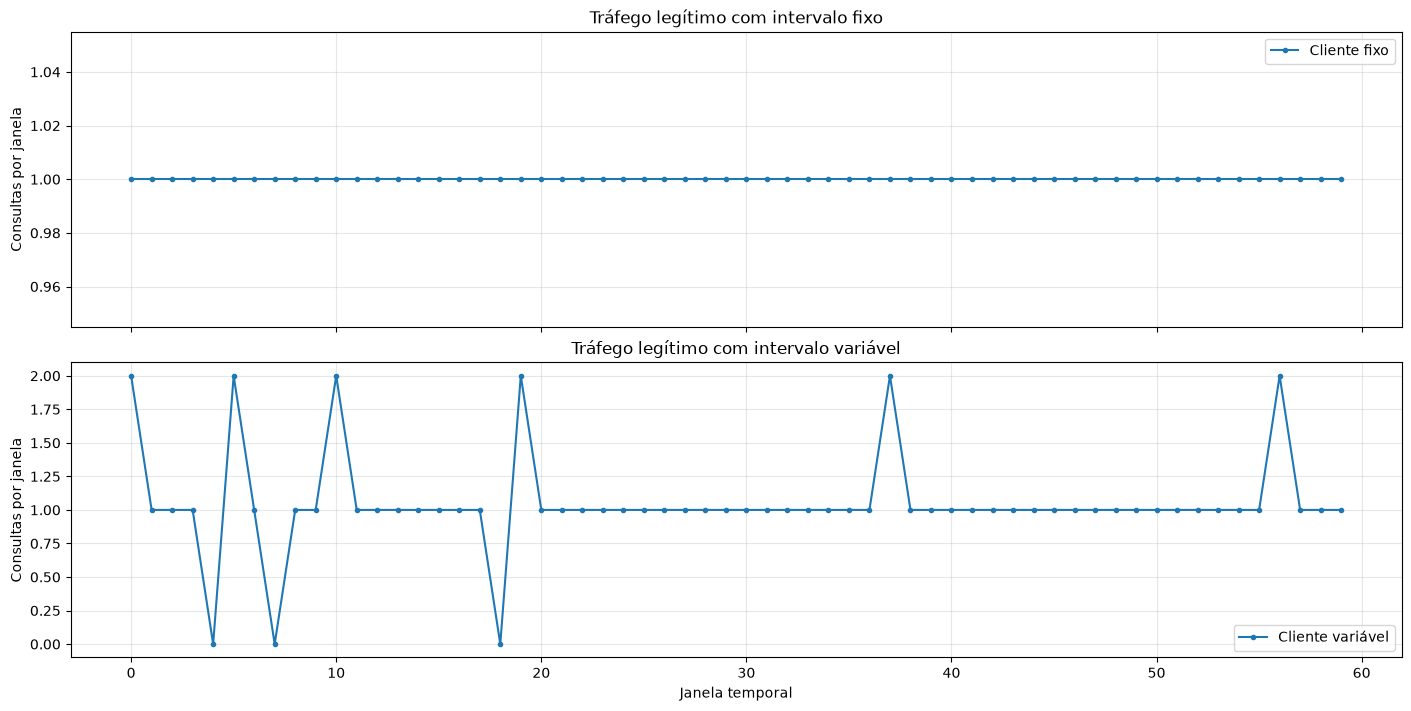

In [8]:
fig, axes = plt.subplots(
    2,
    1,
    figsize=(14, 7),
    sharex=True,
    constrained_layout=True
)

axes[0].plot(
    normal_fixo["janela"],
    normal_fixo["consultas_cliente"],
    marker=".",
    label="Cliente fixo"
)

axes[0].set_title(
    "Tráfego legítimo com intervalo fixo"
)

axes[1].plot(
    normal_variavel["janela"],
    normal_variavel["consultas_cliente"],
    marker=".",
    label="Cliente variável"
)

axes[1].set_title(
    "Tráfego legítimo com intervalo variável"
)

for ax in axes:
    ax.set_ylabel(
        "Consultas por janela"
    )

    ax.grid(alpha=0.3)
    ax.legend()

axes[-1].set_xlabel(
    "Janela temporal"
)

plt.show()